In [2]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


# **CVC-ClinicDB Dataset**

In [3]:
# Dataset Paths
dataset_path = "data/CVC-ClinicDB"
image_dir = "Original"
mask_dir = "Ground Truth"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 612
Number of training samples: 550
Number of testing samples: 62


# Unet CVC model training config

In [4]:
cfg = TrainConfig(
    # --- General ---
    model_name = "ResUNetPP",
    dataset_name = "CVC-ClinicDB",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-3,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [5]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc
wandb: Currently logged in as: mironshoh (iv-drip-counter) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [6]:
model = create_resunetpp(config='standard', in_channels=3, num_classes=1)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-11 08:05:50 | INFO | ResUNetPP_model_CVC_ClinicDB_20250911_080550 | Logging to model_comparisons/logs/ResUNetPP_model_CVC_ClinicDB_20250911_080550.log
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


2025-09-11 08:05:51 | INFO | ResUNetPP_model_CVC_ClinicDB_20250911_080550 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/xp1tafki
100%|██████████| 8/8 [00:01<00:00,  6.15it/s]
2025-09-11 08:06:16 | INFO | ResUNetPP_model_CVC_ClinicDB_20250911_080550 | Epoch 001/100 | Train: 1.028772 | Val: 1.013306 | LR: 0.001000 | 25.20s | Val Dice: 0.3163 IoU: 0.2173 F1: 0.3792
2025-09-11 08:06:16 | INFO | ResUNetPP_model_CVC_ClinicDB_20250911_080550 | Saved best: model_comparisons/models/best_ResUNetPP_model_CVC_ClinicDB_20250911_080550.pth (val=1.013306)
100%|██████████| 8/8 [00:01<00:00,  4.48it/s]
2025-09-11 08:06:43 | INFO | ResUNetPP_model_CVC_ClinicDB_20250911_080550 | Epoch 002/100 | Train: 0.872460 | Val: 1.403560 | LR: 0.001000 | 25.18s | Val Dice: 0.2193 IoU: 0.1480 F1: 0.2922
2025-09-11 08:06:43 | INFO | ResUNetPP_model_CVC_ClinicDB_20250911_080550 | No improvement. ES 1/10
100%|██████████| 8/8 [00:01<00:00,  5.69it/s]
2025-09-11 08:07:07 | INFO | ResUNetPP_model_CVC

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,█▅▄▄▅▂▃▂▂▂▂▂▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▂▁▁▁▁▂▁▂
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▁▄▅▅▃▄▄▆▆▇▇▇▇▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇█▇████▇█▇
epoch_seconds,▇▇▅▃▃▆▁▂▂▃▂▅▆▅▄▃▄▃█▄▅▄▆▄▄▆▅▆▆▆▆▇▆▇▇█▆▇▇█
lr,██████████████████████████████▃▃▃▃▃▃▃▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▂▃▃▄▄▅▅▅▆▆▆▇▇▇▇▇▇▇▇████████████████████
train/f1,▁▂▃▃▃▄▄▅▅▅▆▆▆▇▇▇▇▇▇▇████████████████████
train/iou,▁▂▂▂▂▃▃▄▄▄▅▆▆▆▆▇▇▇▇▇▇▇▇█▇████▇▇█████████
+11,...


{'best_val_loss': 0.15100469812750816,
 'epochs_ran': 54,
 'best_model_path': 'model_comparisons/models/best_ResUNetPP_model_CVC_ClinicDB_20250911_080550.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_ResUNetPP_CVC_ClinicDB_20250911_080550.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/xp1tafki',
 'log_path': 'model_comparisons/logs/ResUNetPP_model_CVC_ClinicDB_20250911_080550.log'}

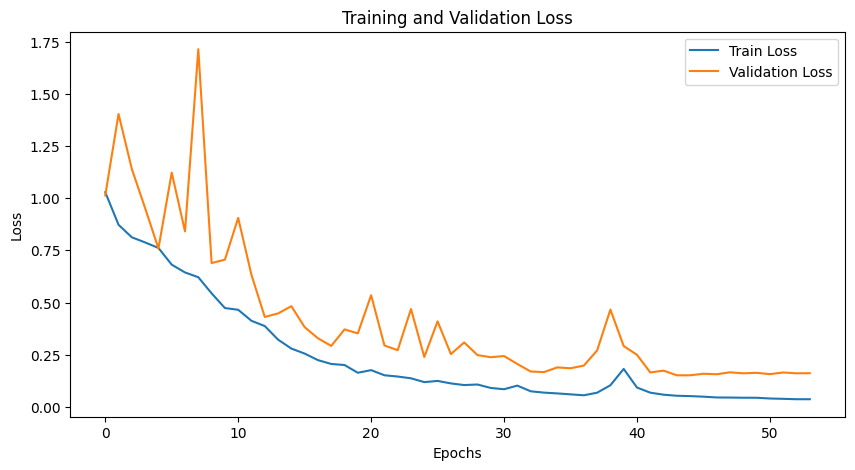

In [7]:
trainer.plot_losses()

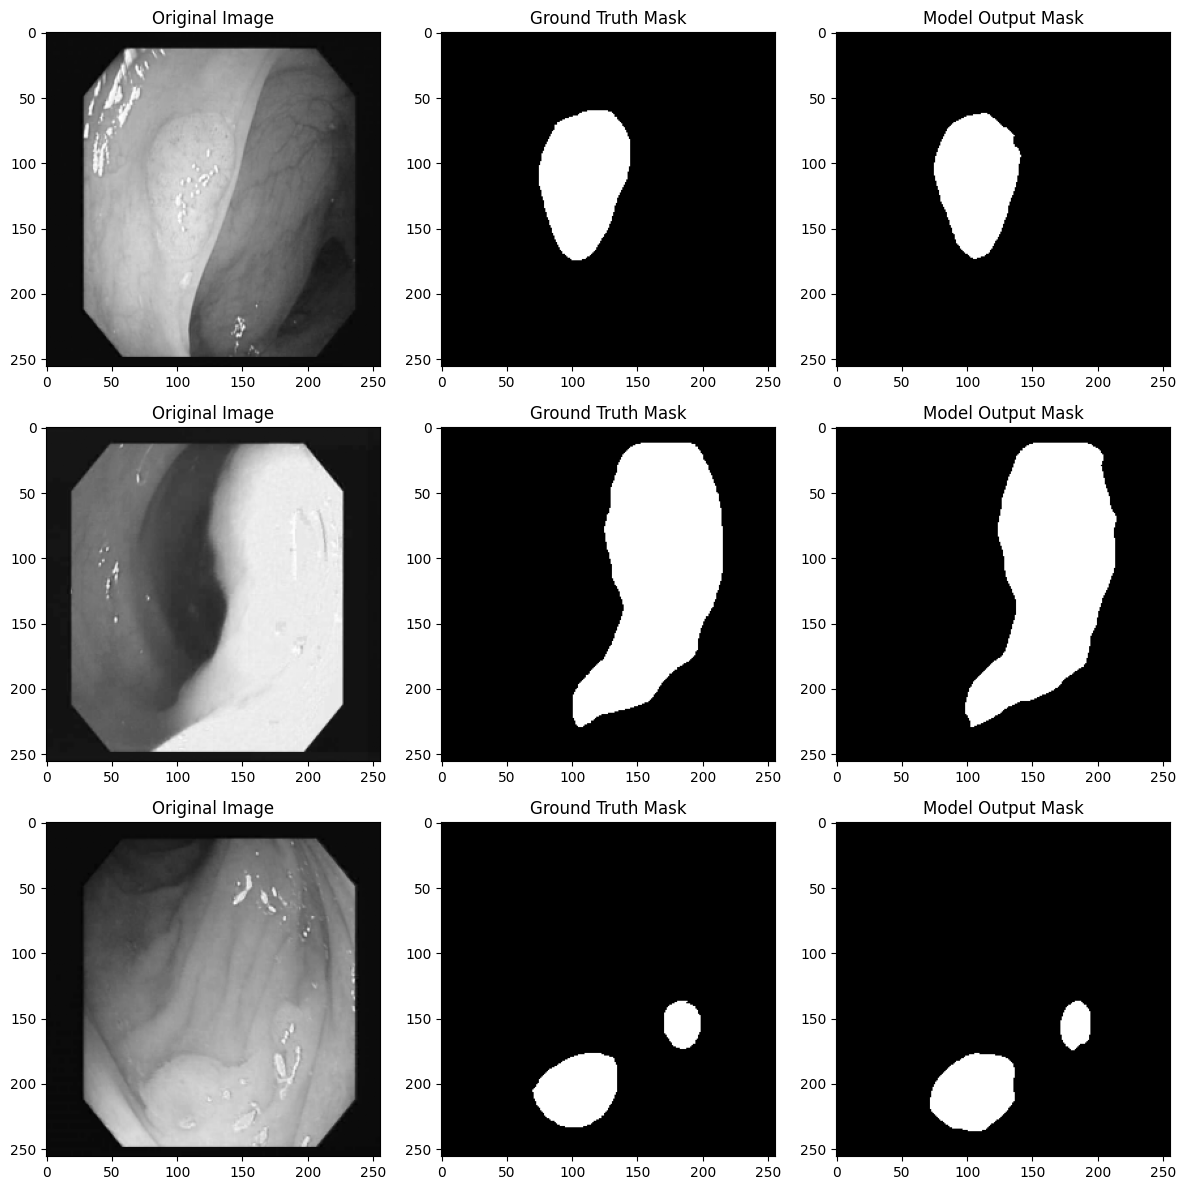

In [8]:
trainer.visualize_output_samples()

In [9]:
trainer.validate_and_save()

100%|██████████| 8/8 [00:01<00:00,  5.52it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.1612
Average Dice Score                 : 0.8907
Average Hausdorff Distance         : inf
Average IoU                        : 0.8277
Precision                          : 0.9604
Recall                             : 0.8822
F1 Score                           : 0.9197
IoU (batch avg)                    : 0.8438
Dice (batch avg)                   : 0.9139
Total Parameters                   : 27,125,221
Trainable Parameters               : 27,125,221
Average Inference Time (seconds)   : 0.074650
FPS (Frames Per Second)            : 13.40
FLOPs                              : 58,868,882,752.0
GFLOPs                             : 58.8689

Results saved to: model_comparisons/evaluation_results/ResUNetPP_model_CVC-ClinicDB_evaluation_results_20250911_080550.csv
Validation results saved to model_comparisons/evaluation_results/ResUNetPP_model_CVC-ClinicDB_evaluation_results


{'test_loss': 0.16119050234556198,
 'avg_dice_score': 0.8907044808718316,
 'avg_hd_score': inf,
 'avg_iou': 0.8276954076951399,
 'precision': 0.9603899036140826,
 'recall': 0.882234638150084,
 'f1': 0.9196547857620002,
 'iou_batch_avg': 0.8438304141163826,
 'dice_batch_avg': 0.9139353856444359,
 'total_params': 27125221,
 'trainable_params': 27125221,
 'avg_inference_time': 0.07465037822723389,
 'fps': 13.3957794152901,
 'flops': 58868882752.0,
 'gflops': 58.868882752}

# **Kvasir-SEG dataset**

In [10]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


In [12]:
# Dataset Paths
dataset_path = "data/Kvasir-SEG"
image_dir = "images"
mask_dir = "masks"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 1000
Number of training samples: 900
Number of testing samples: 100


# UNet Kvasir training config

In [13]:
cfg = TrainConfig(
    # --- General ---
    model_name = "ResUNetPP",
    dataset_name = "Kvasir-SEG",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-3,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [14]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc


In [15]:
model = create_resunetpp(config='standard', in_channels=3, num_classes=1)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-11 08:31:03 | INFO | ResUNetPP_model_Kvasir_SEG_20250911_083103 | Logging to model_comparisons/logs/ResUNetPP_model_Kvasir_SEG_20250911_083103.log


2025-09-11 08:31:03 | INFO | ResUNetPP_model_Kvasir_SEG_20250911_083103 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/6ge3iosr
100%|██████████| 13/13 [00:03<00:00,  4.06it/s]
2025-09-11 08:31:43 | INFO | ResUNetPP_model_Kvasir_SEG_20250911_083103 | Epoch 001/100 | Train: 0.983080 | Val: 0.949303 | LR: 0.001000 | 39.37s | Val Dice: 0.4099 IoU: 0.2897 F1: 0.4466
2025-09-11 08:31:43 | INFO | ResUNetPP_model_Kvasir_SEG_20250911_083103 | Saved best: model_comparisons/models/best_ResUNetPP_model_Kvasir_SEG_20250911_083103.pth (val=0.949303)
100%|██████████| 13/13 [00:02<00:00,  4.92it/s]
2025-09-11 08:32:23 | INFO | ResUNetPP_model_Kvasir_SEG_20250911_083103 | Epoch 002/100 | Train: 0.882323 | Val: 0.919395 | LR: 0.001000 | 38.72s | Val Dice: 0.4754 IoU: 0.3413 F1: 0.5072
2025-09-11 08:32:23 | INFO | ResUNetPP_model_Kvasir_SEG_20250911_083103 | Saved best: model_comparisons/models/best_ResUNetPP_model_Kvasir_SEG_20250911_083103.pth (val=0.919395)
100%|██████████| 13/13

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,█▆▅▅▃▃▄▃▃▃▃▃▃▃▂▂▃▂▂▂▂▂▂▂▃▂▂▁▂▁▁▁▁▁▁▁▂▂
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▁▃▄▄▆▆▅▆▆▆▆▆▆▆▇▇▆▇▇▇▇▇▇▇▆▇▇█▇███████▇▇
epoch_seconds,▅▃▇▁█▁▄▁▅▅▆▅▃▃▃▄▆▄█▄▃▄▄▃▃▂▃▃▃▄▃▃▃▂▄▃▅▄
lr,█████████████████████████████████▁▁▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▂▂▃▃▄▄▄▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇████████████
train/f1,▁▂▂▃▃▄▄▄▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇████████████
train/iou,▁▂▂▂▃▃▃▄▄▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇▇██████████
+11,...


{'best_val_loss': 0.3488977075769351,
 'epochs_ran': 38,
 'best_model_path': 'model_comparisons/models/best_ResUNetPP_model_Kvasir_SEG_20250911_083103.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_ResUNetPP_Kvasir_SEG_20250911_083103.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/6ge3iosr',
 'log_path': 'model_comparisons/logs/ResUNetPP_model_Kvasir_SEG_20250911_083103.log'}

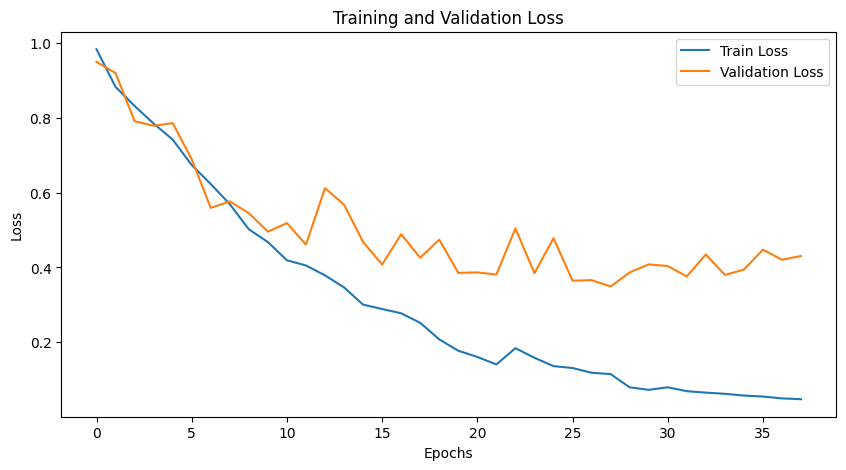

In [16]:
trainer.plot_losses()

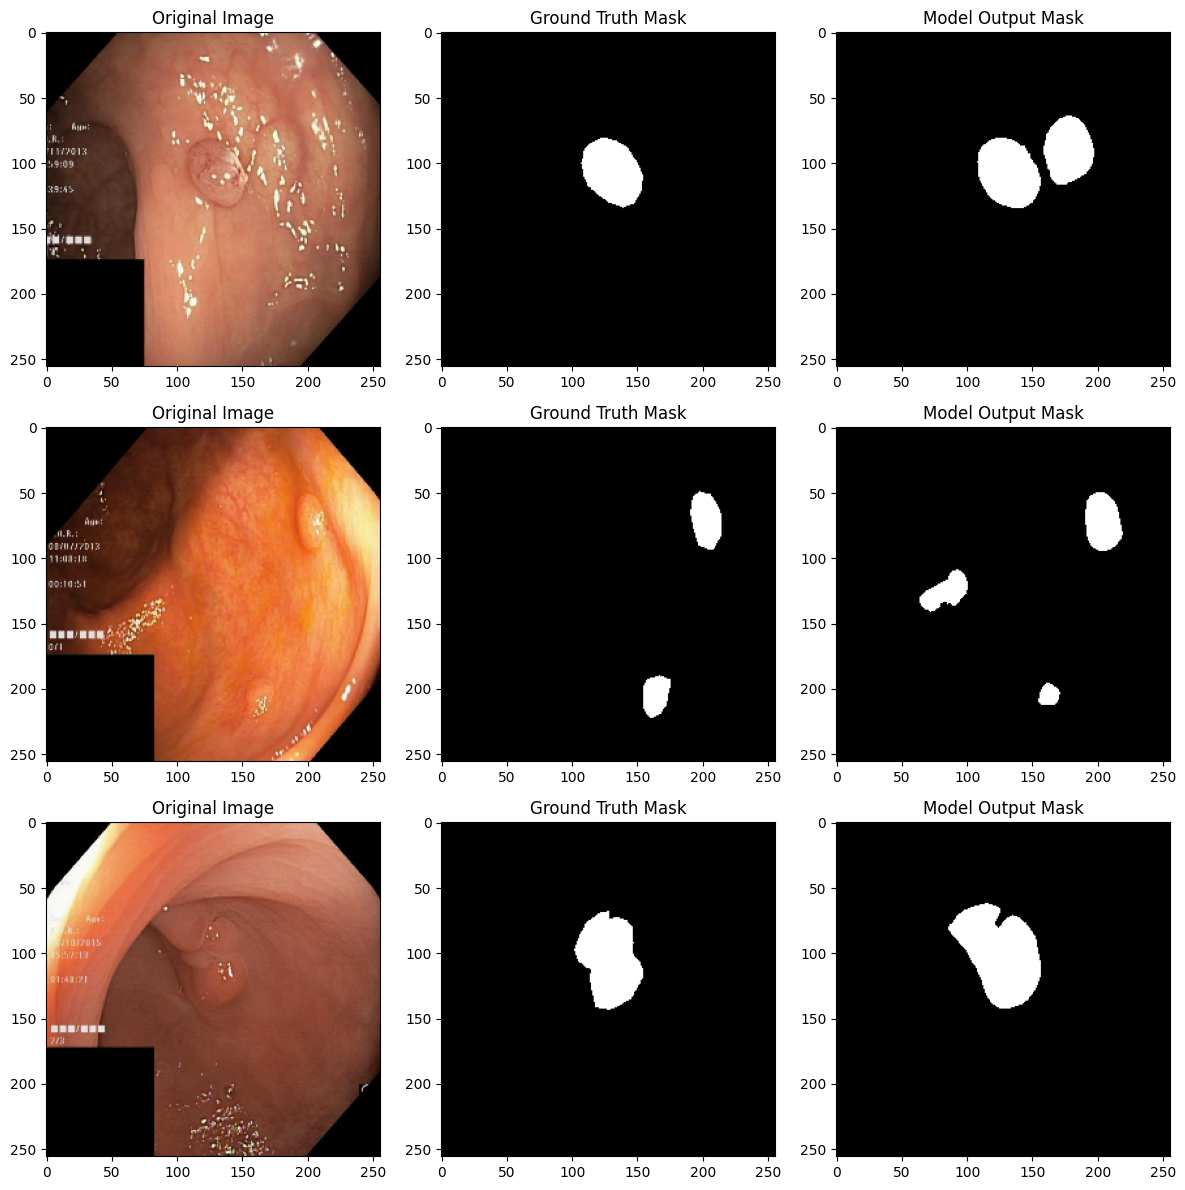

In [17]:
trainer.visualize_output_samples()

In [18]:
trainer.validate_and_save()

100%|██████████| 13/13 [00:03<00:00,  4.08it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.4306
Average Dice Score                 : 0.8302
Average Hausdorff Distance         : inf
Average IoU                        : 0.7549
Precision                          : 0.8992
Recall                             : 0.7732
F1 Score                           : 0.8314
IoU (batch avg)                    : 0.7288
Dice (batch avg)                   : 0.8359
Total Parameters                   : 27,125,221
Trainable Parameters               : 27,125,221
Average Inference Time (seconds)   : 0.074438
FPS (Frames Per Second)            : 13.43
FLOPs                              : 58,868,882,752.0
GFLOPs                             : 58.8689

Results saved to: model_comparisons/evaluation_results/ResUNetPP_model_Kvasir-SEG_evaluation_results_20250911_083103.csv
Validation results saved to model_comparisons/evaluation_results/ResUNetPP_model_Kvasir-SEG_evaluation_results


{'test_loss': 0.43058822590571183,
 'avg_dice_score': 0.8302480951148149,
 'avg_hd_score': inf,
 'avg_iou': 0.7549126577760157,
 'precision': 0.8991564578720456,
 'recall': 0.773156547893981,
 'f1': 0.8314097906169061,
 'iou_batch_avg': 0.7287773673350995,
 'dice_batch_avg': 0.8358578957044162,
 'total_params': 27125221,
 'trainable_params': 27125221,
 'avg_inference_time': 0.07443792343139649,
 'fps': 13.434012582600056,
 'flops': 58868882752.0,
 'gflops': 58.868882752}